# 06 — Stage F: explaining which neighbours a silent turbine relies on

**The challenge in the proposal.** "When a turbine is hidden, which neighbours does the model rely
on? Using attention weights and GNNExplainer, we test whether they lie upwind and shift with the
wind."

**Why this is not free.** Lecture 11 is explicit that attention is a *mechanism*, not an
explanation: it may be unfaithful to the model's decision. So this notebook uses three
attributions with different weaknesses and scores all of them against:

| criterion | question | metric |
|---|---|---|
| **plausibility** | do the attributed neighbours lie upwind? | AUPRC / precision@k vs. the cone-defined upwind set — a *physical*, model-independent ground truth |
| **faithfulness** | does the attribution actually drive the prediction? | sufficiency / comprehensiveness of the top-k edges |
| **sparsity** | is the explanation focused? | normalised entropy of the attribution distribution |

| attribution | how it is computed | weakness |
|---|---|---|
| `attention` | GATv2 coefficients averaged over heads and layers | architectural, may be unfaithful |
| `occlusion` | hide one neighbour at a time, measure the prediction change | expensive, faithful by construction |
| `gnnexplainer` | PyG mask optimisation on the processor (embeddings frozen) | optimiser-dependent, needs a surrogate |

**The one design decision that makes the test meaningful.** Attribution runs on the **soft cone**
(`cone = 180`: every turbine within `R` is a candidate), *not* on the hard cone. If the graph were
already restricted to upwind neighbours, "does the model pick upwind neighbours?" would be
answered by the topology before the model said anything. The 45° cone is then used only as the
**label** of each candidate edge, and the mirrored label ("this neighbour is *downwind*") is the
control: plausible attention must score clearly higher on the upwind label than on the downwind
one.

The `gnnexplainer` path runs on a PyG `GATv2Conv` surrogate that receives the **trained weights**
(notebook 04 verified the batched layer and PyG agree to machine precision), because PyG's
explainer needs `MessagePassing` modules to hook. The explanation therefore refers to the model
that produced the forecast, not to an approximation of it.

## 0. Setup

In [15]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from windgnn import config as C, data as D, graphs as G, tensors as T
from windgnn import models as M, training as TR, evaluation as E, explain as X, viz as V
from windgnn.tensors import WindowSpec, GraphProvider, ForecastWindows, RandomTurbineMasker

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

print("torch", torch.__version__, "| HIP", torch.version.hip, "| CUDA", torch.version.cuda)
print("device:", TR.resolve_device(), "| visible GPUs:", torch.cuda.device_count())
for _i in range(torch.cuda.device_count()):
    print(f"  gpu[{_i}]: {torch.cuda.get_device_name(_i)}")

torch 2.13.0+rocm7.1 | HIP 7.1.52802 | CUDA None
device: cuda | visible GPUs: 2
  gpu[0]: AMD Radeon Graphics
  gpu[1]: AMD Ryzen 5 7600 6-Core Processor


In [16]:
#: "smoke" runs in well under a minute on a slice of the data (pipeline check);
#: "quick" is the default for a first real answer; "full" is the report-quality run.
RUN = os.environ.get("WINDGNN_RUN", "full")
PRESETS = {
    "smoke": dict(train_stride=1997, val_stride=499, samples_per_epoch=32,  epochs=1,  test_stride=1499,
                  seeds=(0,), n_explain=3),
    "quick": dict(train_stride=3,   val_stride=3,   samples_per_epoch=600, epochs=30, test_stride=11,
                  seeds=(0, 1, 2), n_explain=24),
    "full":  dict(train_stride=1,   val_stride=1,   samples_per_epoch=3000, epochs=120, test_stride=1,
                  seeds=(0, 1, 2, 3, 4), n_explain=150),
}
P = PRESETS[RUN]
print(f"RUN = {RUN!r} -> {P}")

RUN = 'full' -> {'train_stride': 1, 'val_stride': 1, 'samples_per_epoch': 3000, 'epochs': 120, 'test_stride': 1, 'seeds': (0, 1, 2, 3, 4), 'n_explain': 150}


In [17]:
SPEC = WindowSpec(input_len=12, horizons=(1, 6, 36))   # 2 h of history; 10 min / 1 h / 6 h ahead
fd = T.build_feature_data()
meta = T.load_graph_meta()
ALPHA, RADIUS = float(meta["alpha_deg"]), float(meta["radius_primary_m"])
print(f"{fd.x.shape[0]:,} timestamps x {fd.n_turbines} turbines x {len(fd.names)} features")
print(f"graph configuration from Stage B: alpha = {ALPHA:.0f} deg, R = {RADIUS:.0f} m, "
      f"cone = {meta['cone_primary_deg']:.0f} deg (primary)")
print("features:", ", ".join(fd.names))

35,280 timestamps x 134 turbines x 15 features
graph configuration from Stage B: alpha = 275 deg, R = 1500 m, cone = 45 deg (primary)
features: patv, wspd, wdir_sin, wdir_cos, etmp, itmp, ndir_sin, ndir_cos, pab1, prtv, farm_sin, farm_cos, tod_sin, tod_cos, observed


In [18]:
# --- the graph used for explanations: the soft (direction-blind) candidate set ---
soft = GraphProvider(fd.loc, fd.farm_dir, fd.t_index, ALPHA, RADIUS, cone_deg=180.0)
hard = GraphProvider(fd.loc, fd.farm_dir, fd.t_index, ALPHA, RADIUS, cone_deg=45.0)  # for labels
print("soft-cone candidate edges:", soft.meta()["n_real_edges"],
      "| mean in-degree (excluding self):",
      round(float(soft.in_degree_batch(np.array([int(soft.t_index[len(soft.t_index)//2])])).mean()), 2))

# --- the model trained in notebook 04 (or a small one, if that notebook has not been run) ---
MODEL_CFG = dict(graph="gatv2", d=64, n_layers=2, heads=4, edge_dim=4,
                 dropout=0.0, hidden_placeholder="learnable", residual_persistence=True)
model = M.build_model(MODEL_CFG, n_features=len(fd.names), n_horizons=len(SPEC.horizons),
                      patv_feature=fd.feature_index("patv"))
ckpt_name = "stage_d_soft"
try:
    ckpt_meta = TR.load_checkpoint(model, ckpt_name, 0)
    print(f"loaded {TR.checkpoint_path(ckpt_name, 0).name} | run={ckpt_meta.get('run')!r} "
          f"| best val {ckpt_meta.get('best_val_kW', float('nan')):.1f} kW")
    if ckpt_meta.get("run") != RUN:
        print(f"WARNING: this checkpoint was trained with run={ckpt_meta.get('run')!r}, not "
              f"{RUN!r} - re-run notebook 04 with WINDGNN_RUN={RUN} to explain that model")
except FileNotFoundError:
    print("checkpoint not found -> training a small model for this notebook")
    tr_t, tr_h = T.sample_indices(fd, SPEC, "train", stride=P["train_stride"])
    va_t, va_h = T.sample_indices(fd, SPEC, "val", stride=P["val_stride"])
    trainer = TR.fit_model(
        model,
        ForecastWindows(fd, tr_t, tr_h, SPEC, masker=RandomTurbineMasker(0.5, seed=0)),
        ForecastWindows(fd, va_t, va_h, SPEC, masker=RandomTurbineMasker(0.5, seed=1)),
        soft, TR.TrainConfig(epochs=P["epochs"], samples_per_epoch=P["samples_per_epoch"],
                             seed=0, verbose=False), fd)
    TR.save_checkpoint(trainer, ckpt_name, 0)
print(model.describe())

soft-cone candidate edges: 1458 | mean in-degree (excluding self): 10.88
loaded stage_d_soft_seed0.pt | run='full' | best val 157.3 kW
WindForecaster(graph=gatv2, layers=2, d=64, horizons=3, edge_dim=4, params=48,067)


## 1. Which (turbine, window) pairs to explain

A silent turbine can only be explained where it has a scoreable target. The sample below covers
two regimes the hypotheses distinguish: windows where the turbine has several **upwind**
neighbours (deep inside the array) and windows where it has none (front row) — computed with the
hard cone, i.e. the physical exposure, not the model's candidate set.

In [19]:
test_t, test_h = T.sample_indices(fd, SPEC, "test", stride=max(P["test_stride"], 3))
H_EXPLAIN = 6                      # 1 h ahead
keep = test_h == H_EXPLAIN
cand_t = test_t[keep]
deg = hard.in_degree_batch(cand_t)                  # (n_windows, N) physical exposure
rng = np.random.default_rng(0)

cases = []
for want_zero in (False, True):
    for _ in range(max(1, P["n_explain"] // 2)):
        t_idx = rng.integers(0, len(cand_t))
        row = deg[t_idx]
        pool = np.flatnonzero((row == 0) if want_zero else (row >= 4))
        if pool.size == 0:
            continue
        tid = int(pool[rng.integers(0, pool.size)]) + 1
        cases.append({"t_end": int(cand_t[t_idx]), "TurbID": tid,
                      "in_degree": int(row[tid - 1]), "front_row": bool(want_zero)})
cases = pd.DataFrame(cases).drop_duplicates(["t_end", "TurbID"])
print(f"{len(cases)} explanations at h = {H_EXPLAIN*10} min")

def window_and_graph(t_end, tid):
    """One hidden-turbine window plus the soft-cone graph at that timestamp."""
    mask = np.zeros((1, fd.n_turbines), dtype=bool)
    mask[0, tid - 1] = True
    ds = ForecastWindows(fd, np.array([t_end]), np.array([H_EXPLAIN]), SPEC, fixed_hidden=mask)
    item = ds[0]
    return item["x"].numpy(), item["hidden"].numpy(), X.explain_graph(soft, t_end)

display(cases.head(10))

150 explanations at h = 60 min


,t_end,TurbID,in_degree,front_row
0,34223,65,4,False
1,31832,26,4,False
2,30401,2,4,False
3,28763,29,4,False
4,29468,93,4,False
5,32807,91,4,False
6,31781,46,4,False
7,35069,113,4,False
8,32684,47,4,False
9,32177,91,4,False


## 2. Attention attribution

For a silent turbine `j`, the attention weights on the edges `i -> j` are averaged over heads and
layers. Two questions: are the most-attended neighbours the **upwind** ones (AUPRC against the
45° cone, with the mirrored downwind label as the control), and is the distribution sharp
(sparsity)?

In [20]:
HI = SPEC.horizons.index(H_EXPLAIN)
att_rows, att_objects = [], []
for _, c in cases.iterrows():
    t, tid = int(c.t_end), int(c.TurbID)
    x, hidden, g = window_and_graph(t, tid)
    a = X.attention_attribution(model, x, soft, g, hidden, tid, HI)
    pu = X.plausibility(a, 45.0, "upwind")
    pdc = X.plausibility(a, 45.0, "downwind")
    att_objects.append((c, a))
    att_rows.append({"TurbID": tid, "t_end": t, "in_degree": int(c.in_degree),
                     "front_row": bool(c.front_row), "n_candidates": len(a),
                     "n_upwind": pu["n_upwind"], "n_downwind": pdc["n_upwind"],
                     "auprc_upwind": pu["auprc"], "precision_at_k_upwind": pu["precision_at_k"],
                     "auprc_downwind": pdc["auprc"],
                     "sparsity": X.sparsity(a.scores)})
att = pd.DataFrame(att_rows)
att.to_csv(C.TABLES_DIR / "stage_f_attention.csv", index=False)
display(att.round(3))
ok_up = att.auprc_upwind.notna().sum()
print(f"attention AUPRC vs upwind: {E.fmt(E.safe_mean(att.auprc_upwind))} "
      f"({ok_up}/{len(att)} cases carry both classes)")
print(f"control label (downwind): {E.fmt(E.safe_mean(att.auprc_downwind))}")
print(f"chance level (share of upwind candidates): {(att.n_upwind / att.n_candidates).mean():.3f}")

,TurbID,t_end,in_degree,front_row,n_candidates,n_upwind,n_downwind,auprc_upwind,precision_at_k_upwind,auprc_downwind,sparsity
0,65,34223,4,False,12,4,0,0.229,0.00,NaN,1.000
1,26,31832,4,False,14,4,4,0.194,0.00,0.733,1.000
2,2,30401,4,False,13,4,2,0.229,0.00,0.500,0.999
3,29,28763,4,False,10,4,0,0.282,0.00,NaN,1.000
4,93,29468,4,False,15,4,3,0.180,0.00,0.810,1.000
5,91,32807,4,False,15,4,3,0.184,0.00,1.000,1.000
6,46,31781,4,False,16,4,3,0.167,0.00,0.867,1.000
7,113,35069,4,False,10,4,0,0.318,0.00,NaN,1.000
8,47,32684,4,False,15,4,3,0.181,0.00,0.917,1.000
9,91,32177,4,False,15,4,3,0.180,0.00,1.000,0.999


attention AUPRC vs upwind: 0.226 (75/150 cases carry both classes)
control label (downwind): 0.738
chance level (share of upwind candidates): 0.153


/tmp/ipykernel_75800/2981504874.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(); V.save_figure(fig, "stage_f_attention_structure"); plt.show()


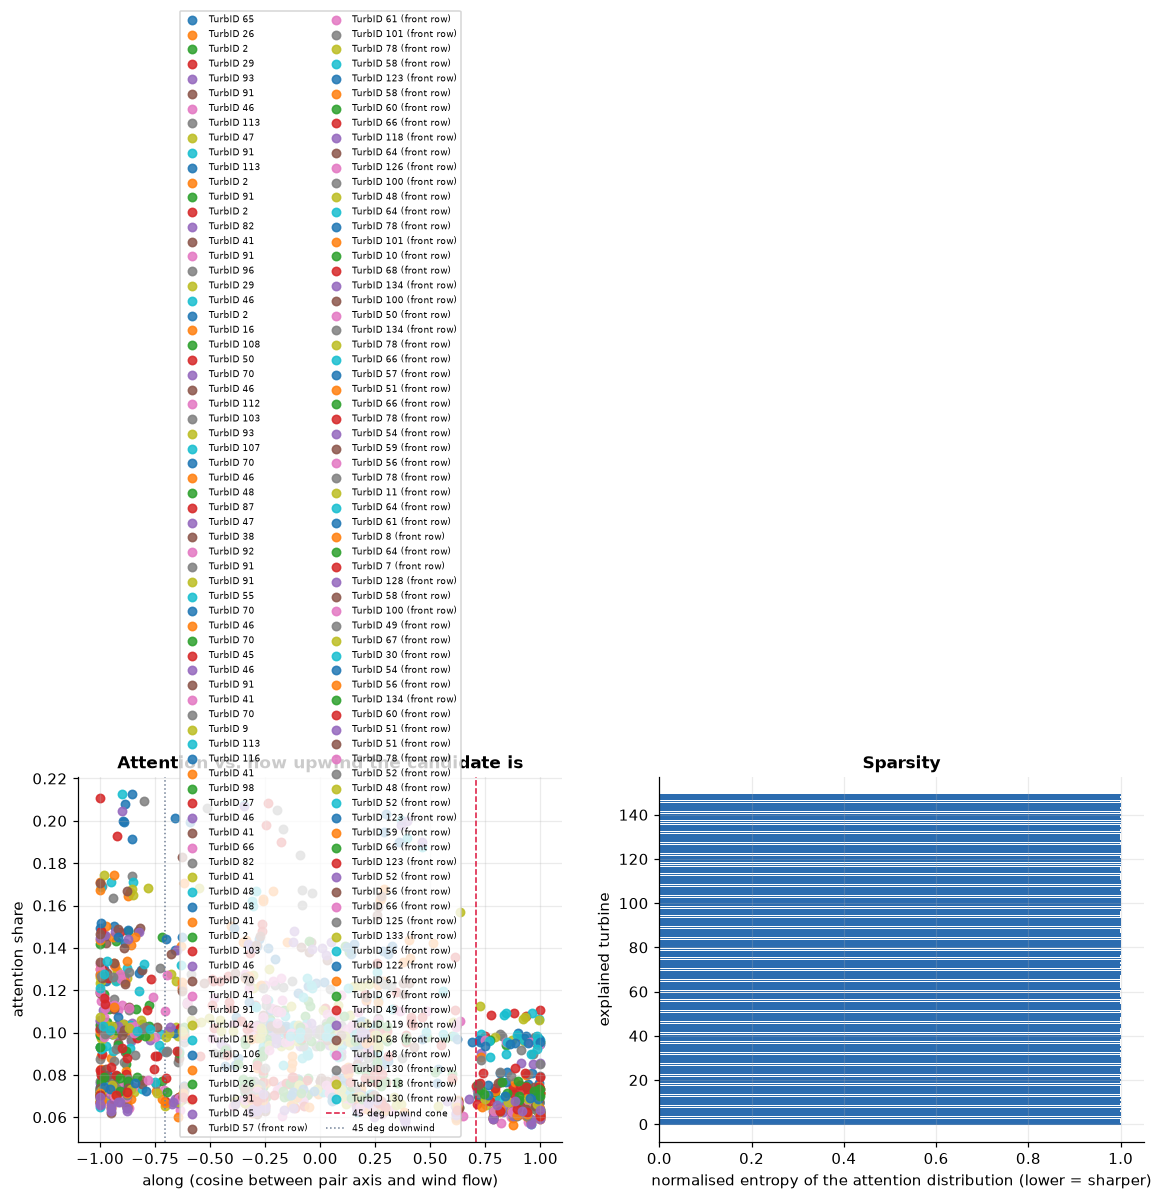

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for c, a in att_objects:
    share = a.scores / max(a.scores.sum(), 1e-9)
    axes[0].scatter(a.edge_attr[:, 1], share, s=30, alpha=.85,
                    label=f"TurbID {c.TurbID}" + (" (front row)" if c.front_row else ""))
axes[0].axvline(np.cos(np.deg2rad(45)), color="crimson", ls="--", lw=1, label="45 deg upwind cone")
axes[0].axvline(-np.cos(np.deg2rad(45)), color="#718096", ls=":", lw=1, label="45 deg downwind")
axes[0].set(xlabel="along (cosine between pair axis and wind flow)", ylabel="attention share",
            title="Attention vs. how upwind the candidate is")
axes[0].legend(fontsize=6, ncol=2); axes[0].grid(alpha=.25)

axes[1].barh(range(len(att)), att.sparsity, color="#2b6cb0")
axes[1].set(xlabel="normalised entropy of the attention distribution (lower = sharper)",
            ylabel="explained turbine", title="Sparsity")
axes[1].grid(alpha=.25, axis="x")
fig.tight_layout(); V.save_figure(fig, "stage_f_attention_structure"); plt.show()

## 3. Occlusion and GNNExplainer

Occlusion measures what the *model* does: hide one neighbour's whole input window and record the
prediction change at the silent turbine (in kW). GNNExplainer optimises an edge mask directly on
the frozen embeddings. Both are far more expensive than attention, so they run on a subset of the
same cases.

In [22]:
st = fd.stats.set_index("feature").loc["patv"]
STD, MEAN = float(st["std"]), float(st["mean"])

subset = cases.head(max(2, min(len(cases), P["n_explain"] // 2 + 1)))
rows, per_method = [], {}
for _, c in subset.iterrows():
    t, tid = int(c.t_end), int(c.TurbID)
    x, hidden, g = window_and_graph(t, tid)
    occ = X.occlusion_attribution(model, x, soft, g, hidden, tid, HI,
                                  target_std=STD, target_mean=MEAN)
    gnn = X.gnnexplainer_attribution(model, x, soft, g, hidden, tid, HI, epochs=50)
    # attention on the *same* cases, so the three methods are compared on equal footing
    att_same = X.attention_attribution(model, x, soft, g, hidden, tid, HI)
    per_method[("occlusion", tid, t)] = occ
    per_method[("gnnexplainer", tid, t)] = gnn
    for name, a in (("attention", att_same), ("occlusion", occ), ("gnnexplainer", gnn)):
        pu = X.plausibility(a, 45.0, "upwind")
        pdc = X.plausibility(a, 45.0, "downwind")
        rows.append({"method": name, "TurbID": tid, "t_end": t,
                     "in_degree": int(c.in_degree), "n_candidates": len(a),
                     "auprc_upwind": pu["auprc"], "auprc_downwind": pdc["auprc"],
                     "precision_at_k_upwind": pu["precision_at_k"],
                     "sparsity": X.sparsity(a.scores),
                     "top_neighbour_kW": float(np.max(a.scores)) if len(a) else np.nan})
extra = pd.DataFrame(rows)
extra.to_csv(C.TABLES_DIR / "stage_f_occlusion_gnnexplainer.csv", index=False)
display(extra.round(3))

,method,TurbID,t_end,in_degree,n_candidates,auprc_upwind,auprc_downwind,precision_at_k_upwind,sparsity,top_neighbour_kW
0,attention,65,34223,4,12,0.229,NaN,0.00,1.000,0.082
1,occlusion,65,34223,4,12,0.555,NaN,0.25,0.982,12.138
2,gnnexplainer,65,34223,4,12,0.377,NaN,0.25,0.999,0.397
3,attention,26,31832,4,14,0.194,0.733,0.00,1.000,0.075
4,occlusion,26,31832,4,14,0.467,0.321,0.25,0.832,35.363
...,...,...,...,...,...,...,...,...,...,...
223,occlusion,45,29612,4,15,0.530,0.175,0.50,0.921,19.704
224,gnnexplainer,45,29612,4,15,0.238,0.261,0.00,0.999,0.421
225,attention,57,28583,0,7,NaN,0.950,NaN,1.000,0.134
226,occlusion,57,28583,0,7,NaN,0.451,NaN,0.933,76.863


In [23]:
display(extra.groupby("method", observed=True)
        .agg(n=("TurbID", "size"), sparsity=("sparsity", "mean"),
             auprc_upwind=("auprc_upwind", "mean"), auprc_downwind=("auprc_downwind", "mean"),
             precision_at_k=("precision_at_k_upwind", "mean")).round(3))

,n,sparsity,auprc_upwind,auprc_downwind,precision_at_k
method,,,,,
attention,76,1.000,0.226,0.735,0.017
gnnexplainer,76,0.998,0.438,0.324,0.289
occlusion,76,0.905,0.414,0.365,0.275


## 4. Faithfulness — do the attributed edges actually drive the prediction?

For the top-k attributed candidate edges (k = 3) of the silent turbine:

* **sufficiency** — keep *only* those edges (plus self-loops): the prediction should barely move;
* **comprehensiveness** — remove them: the prediction should move a lot.

Both are in kW, relative to the full-graph prediction. A faithful attribution has a small
sufficiency delta and a large comprehensiveness delta. This is the test that decides whether an
attention map can be trusted as an explanation.

In [24]:
K = 3
faith_rows = []
for _, c in subset.iterrows():
    t, tid = int(c.t_end), int(c.TurbID)
    x, hidden, g = window_and_graph(t, tid)
    methods = {"attention": X.attention_attribution(model, x, soft, g, hidden, tid, HI),
               "occlusion": per_method[("occlusion", tid, t)],
               "gnnexplainer": per_method[("gnnexplainer", tid, t)]}
    for name, a in methods.items():
        keep_mask = X.top_k_mask(a, soft.n_edges, K, provider=soft)
        eff = X.edge_subset_effect(model, x, g, hidden, tid, HI, keep_mask,
                                   target_std=STD, target_mean=MEAN)
        faith_rows.append({"method": name, "TurbID": tid, "k": K, **eff})
faith = pd.DataFrame(faith_rows)
faith.to_csv(C.TABLES_DIR / "stage_f_faithfulness.csv", index=False)
display(faith.groupby("method", observed=True)[["kept_delta_kW", "removed_delta_kW"]]
        .agg(["mean", "std"]).round(2))
print("sufficiency = |kept_delta| (small is good); comprehensiveness = |removed_delta| (large is good)")

kept_delta_kW        removed_delta_kW       
                      mean    std             mean    std
method                                                   
attention            -8.00  71.41             5.46  19.25
gnnexplainer          9.64  88.19            -0.75  25.39
occlusion            16.22  98.08            -1.43  22.44

sufficiency = |kept_delta| (small is good); comprehensiveness = |removed_delta| (large is good)


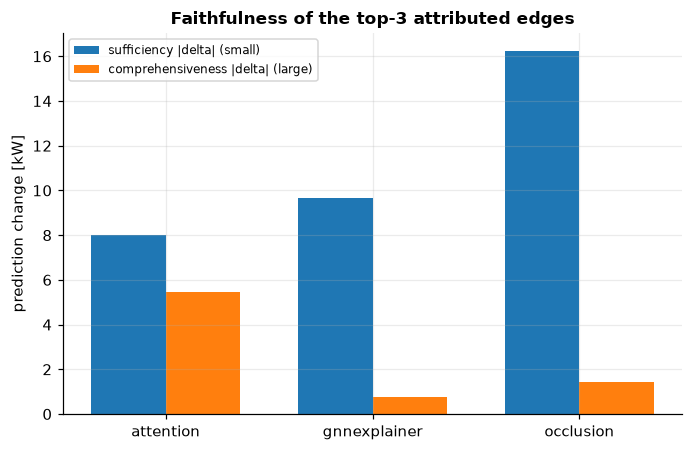

In [25]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
g_faith = faith.groupby("method", observed=True)[["kept_delta_kW", "removed_delta_kW"]].mean()
xpos = np.arange(len(g_faith))
ax.bar(xpos - .18, g_faith.kept_delta_kW.abs(), width=.36, label="sufficiency |delta| (small)")
ax.bar(xpos + .18, g_faith.removed_delta_kW.abs(), width=.36, label="comprehensiveness |delta| (large)")
ax.set_xticks(xpos); ax.set_xticklabels(g_faith.index)
ax.set(ylabel="prediction change [kW]", title=f"Faithfulness of the top-{K} attributed edges")
ax.legend(fontsize=8); ax.grid(alpha=.25, axis="y")
fig.tight_layout(); V.save_figure(fig, "stage_f_faithfulness"); plt.show()

## 5. Does the explanation rotate with the wind?

The proposal's strongest explainability claim. The turbine is fixed and only the wind sector
changes. Because the graph is the *direction-blind* soft cone, any rotation in the attention must
come from the model reading the edge features — not from the topology.

The honest way to score it is the **difference between two labels**: for the same attention map,
AUPRC against "the upwind cone" minus AUPRC against "the downwind cone". A direction-aware model
scores positive; a model that ignores the direction scores ≈ 0.

In [26]:
N_SECTORS = 8
dirs = fd.farm_dir[test_t]
sec_all = G.sector_index(dirs, N_SECTORS)
tid = int(cases.TurbID.iloc[0])
rows = []
for sector in range(N_SECTORS):
    tt = test_t[(sec_all == sector) & keep]
    if len(tt) == 0:
        continue
    t = int(tt[0])
    x, hidden, g = window_and_graph(t, tid)
    a = X.attention_attribution(model, x, soft, g, hidden, tid, HI)
    pu = X.plausibility(a, 45.0, "upwind")
    pdc = X.plausibility(a, 45.0, "downwind")
    difference = (pu["auprc"] - pdc["auprc"]
                  if np.isfinite(pu["auprc"]) and np.isfinite(pdc["auprc"]) else np.nan)
    rows.append({"sector": sector,
                 "sector_center_deg": float(G.sector_centers(N_SECTORS)[sector]),
                 "auprc_upwind": pu["auprc"], "auprc_downwind": pdc["auprc"],
                 "difference": difference,
                 "n_candidates": len(a), "n_upwind": pu["n_upwind"]})
circ = pd.DataFrame(rows)
circ.to_csv(C.TABLES_DIR / "stage_f_rotation.csv", index=False)
display(circ.round(3))
n_diff = int(circ.difference.notna().sum())
print(f"mean (AUPRC upwind - AUPRC downwind) = {E.fmt(E.safe_mean(circ.difference))} "
      f"over {n_diff} sectors where both labels are populated")
print("positive => attention favours upwind candidates; ~0 => the model ignores the direction")

,sector,sector_center_deg,auprc_upwind,auprc_downwind,difference,n_candidates,n_upwind
0,0,22.5,NaN,0.388,NaN,12,0
1,1,67.5,0.177,0.542,-0.364,12,3
2,2,112.5,0.286,0.867,-0.581,12,5
3,3,157.5,0.243,NaN,NaN,12,4
4,4,202.5,0.252,NaN,NaN,12,4
5,5,247.5,0.177,NaN,NaN,12,3
6,6,292.5,0.199,0.967,-0.767,12,3
7,7,337.5,NaN,0.841,NaN,12,0


mean (AUPRC upwind - AUPRC downwind) = -0.571 over 3 sectors where both labels are populated
positive => attention favours upwind candidates; ~0 => the model ignores the direction


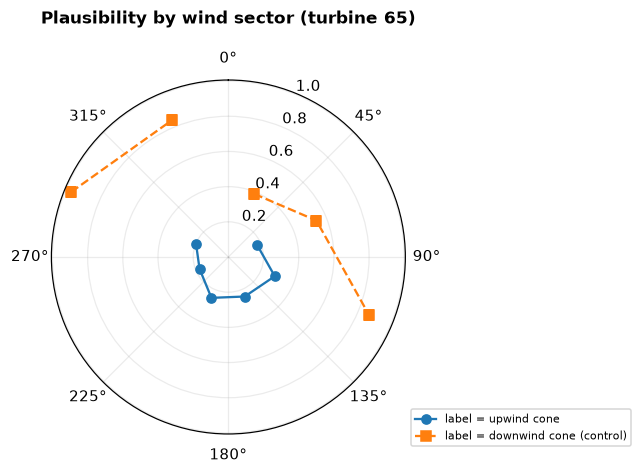

In [27]:
if len(circ) >= 3:
    fig = plt.figure(figsize=(5.6, 5.2))
    ax = fig.add_subplot(111, projection="polar")
    ax.plot(np.deg2rad(circ.sector_center_deg), circ.auprc_upwind, "o-", label="label = upwind cone")
    ax.plot(np.deg2rad(circ.sector_center_deg), circ.auprc_downwind, "s--",
            label="label = downwind cone (control)")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(f"Plausibility by wind sector (turbine {tid})", pad=18)
    ax.legend(fontsize=7, loc="lower left", bbox_to_anchor=(1.0, -0.05))
    fig.tight_layout(); V.save_figure(fig, "stage_f_rotation"); plt.show()
else:
    print("too few wind sectors with test windows at this stride; raise the run mode")

## 6. What can and cannot be claimed

* **Attention is evidence, not proof.** The sufficiency/comprehensiveness table decides whether
  the attention map corresponds to the model's decision. Where the two disagree, report the
  disagreement — that is exactly the Lecture 11 point.
* **The ground truth is physical but weak.** Stage B measured the wake deficit at
  `+1.45 ± 1.91 kW` (1 km) and `−0.24 ± 1.22 kW` (1.5 km): on this dense, highly correlated farm
  the upwind/downwind contrast is buried in shared wind variability. A plausibility score close to
  chance therefore says as much about the farm as about the model, which is why the downwind
  control is reported alongside every number.
* **Soft cone, not hard cone.** The candidate set is direction-blind by construction, so the
  explanation measures what the model *chose*, not what the graph *allowed*. Repeating the same
  measurement on the hard cone would be circular.
* **Scope.** Explanations are per turbine, per window and per horizon; the aggregated numbers are
  what can be reported, a single attention map is an anecdote.

In [28]:
out = {
    "n_explanations": int(len(att)),
    "attention_auprc_upwind_mean": E.safe_mean(att.auprc_upwind),
    "attention_auprc_downwind_mean": E.safe_mean(att.auprc_downwind),
    "attention_sparsity_mean": E.safe_mean(att.sparsity),
    "methods": extra.groupby("method", observed=True)["auprc_upwind"].mean().round(3).to_dict(),
    "faithfulness": (faith.groupby("method", observed=True)[["kept_delta_kW", "removed_delta_kW"]]
                     .mean().round(2).to_dict()),
    "rotation_difference_mean": E.safe_mean(circ.difference) if len(circ) else None,
    "rotation_sectors_scored": int(circ.difference.notna().sum()) if len(circ) else 0,
}
(C.TABLES_DIR / "stage_f_summary.json").write_text(
    json.dumps(E.nan_to_none(out), indent=2, default=str))
print(json.dumps(E.nan_to_none(out), indent=2, default=str))

{
  "n_explanations": 150,
  "attention_auprc_upwind_mean": 0.22574837199837194,
  "attention_auprc_downwind_mean": 0.7378779141865079,
  "attention_sparsity_mean": 0.9996536311627646,
  "methods": {
    "attention": 0.226,
    "gnnexplainer": 0.438,
    "occlusion": 0.414
  },
  "faithfulness": {
    "kept_delta_kW": {
      "attention": -8.0,
      "gnnexplainer": 9.64,
      "occlusion": 16.22
    },
    "removed_delta_kW": {
      "attention": 5.46,
      "gnnexplainer": -0.75,
      "occlusion": -1.43
    }
  },
  "rotation_difference_mean": -0.570993265993266,
  "rotation_sectors_scored": 3
}
